In [1]:
import numpy as np
import netCDF4 as nc

import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
file = Path("~/era5_t2m_monthly/era5_t2m_1940-01.nc").expanduser()
dataset = nc.Dataset(str(file), mode="r")

In [3]:
print(dataset.variables.keys())

dict_keys(['number', 'valid_time', 'latitude', 'longitude', 'expver', 't2m'])


dict_keys(['number', 'valid_time', 'latitude', 'longitude', 'expver', 't2m'])
Temperature shape: (1, 721, 1440)
K


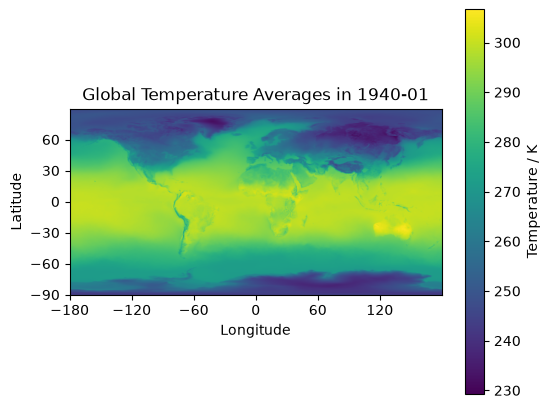

In [4]:
with nc.Dataset(str(file), "r") as ds:
    print(ds.variables.keys())

    lat = ds.variables["latitude"][:]
    lon = ds.variables["longitude"][:]
    temp = ds.variables["t2m"][:]

    lon = (lon + 180) % 360 - 180

    lon_order = np.argsort(lon)

    lon = lon[lon_order]
    temp = temp[:, :, lon_order]

    print("Temperature shape:", temp.shape)
    print(ds.variables["t2m"].units)

    plt.figure(figsize=(6, 5))
    heatmap = plt.imshow(
        temp[0],
        extent=[lon.min(), lon.max(), lat.min(), lat.max()]
    )

    plt.colorbar(heatmap, label='Temperature / K')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Global Temperature Averages in 1940-01')
    plt.xticks(np.arange(-180, 180, 60))
    plt.yticks(np.arange(-90, 90, 30))
    plt.show()

In [5]:
import xarray as xr
folder = Path("~/era5_t2m_monthly").expanduser()

files = sorted(folder.glob("era*.nc"))

ds = xr.open_mfdataset(
    files,
    combine="by_coords"
)

print(ds.variables.keys())

KeysView(Frozen({'t2m': <xarray.Variable (valid_time: 1032, latitude: 721, longitude: 1440)> Size: 4GB
dask.array<concatenate, shape=(1032, 721, 1440), dtype=float32, chunksize=(1, 721, 1440), chunktype=numpy.ndarray>
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0, 'number': <xarray.Variable ()> Size: 8B
array(0)
Attributes:
    long_name:      ensemble 

In [6]:
temp = ds.variables["t2m"][:]

In [7]:
print(temp.shape)

(1032, 721, 1440)


In [8]:
len(files)

1032

In [37]:
oxford_temps = temp[:, 153, int(1440/2) - 5]

In [38]:
oxford_temps.shape

(1032,)

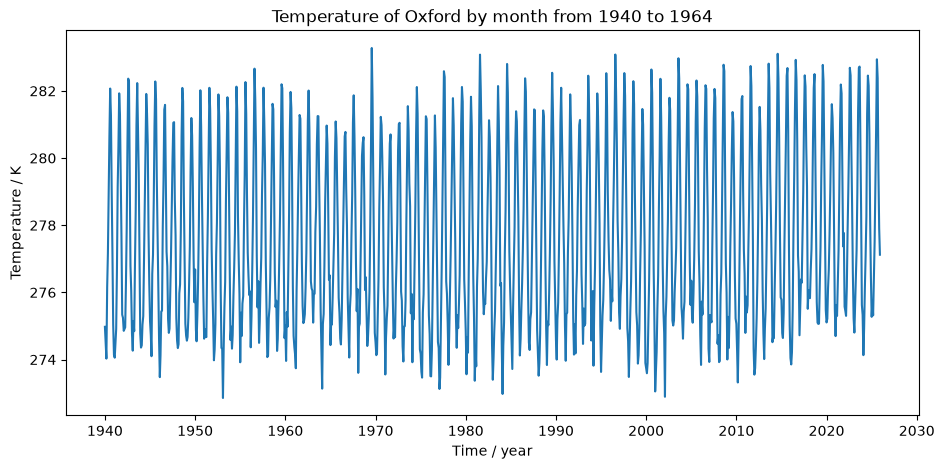

In [69]:
times = ds.variables["valid_time"].to_numpy()

plt.figure(figsize=(11, 5))
plt.plot(times, oxford_temps)
plt.xlabel("Time / year")
plt.ylabel("Temperature / K")
plt.title("Temperature of Oxford by month from 1940 to 1964")
plt.show()